## LIME: Local Explainability Using Python

**Dataset:** Pima Indians Diabetes | **Model:** Random Forest Classifier | **Environment:** Google Colab

### Learning objectives
By the end of this notebook, you should be able to:
1. Explain why individual predictions need explanations.
2. Describe the main idea behind LIME.
3. Prepare the Pima Indians Diabetes dataset.
4. Train and evaluate a Random Forest classifier.
5. Generate and interpret a LIME explanation.
6. Identify limitations of LIME.

**Problem statement:** A hospital's model predicts whether a patient has diabetes. The doctor wants to understand why the model made a particular prediction for one patient.


## 1. Why do we need LIME?

A prediction such as *Diabetes* or *No Diabetes* does not tell us which input features influenced the model for a particular patient. Two patients may receive the same predicted class for different reasons.

**LIME** stands for **Local Interpretable Model-Agnostic Explanations**.

- **Local:** Explains model behaviour around one selected instance.
- **Interpretable:** Uses a simpler explanation that people can understand.
- **Model-agnostic:** Explains a model through its input-output behaviour, without requiring access to its internal structure.

**Key idea:** LIME generates modified samples around the instance, obtains predictions from the original model, weights samples by proximity, and fits a simple local model to approximate the original model near that instance.

LIME does not simply change one feature at a time and rank prediction changes. It uses many samples and a proximity-weighted local approximation.

## 2. How LIME works

1. Select the instance to explain.
2. Generate modified samples around it.
3. Obtain predictions for those samples from the original model.
4. Give greater weight to samples closer to the selected instance.
5. Fit a simple interpretable surrogate model locally.
6. Use the surrogate model's feature weights to explain the prediction.

**Workflow:** Patient record → Modified samples → Original model predictions → Proximity weighting → Local surrogate → Explanation.

## 3. Mathematical intuition

LIME searches for an interpretable model that approximates the original model in the neighbourhood of the selected instance:

$$
\xi(x)=\arg\min_{g\in G}\left[L(f,g,\pi_x)+\Omega(g)\right]
$$

- \(x\): instance being explained.
- \(f\): original machine learning model.
- \(g\): interpretable local explanation model.
- \(G\): family of interpretable models.
- \(\pi_x\): proximity measure, giving greater importance to samples near \(x\).
- \(L\): weighted loss measuring how closely \(g\) approximates \(f\) locally.
- \(\Omega(g)\): complexity penalty favouring simpler explanations.

The explanation is local; it does not claim that the surrogate represents the original model across the entire dataset.

## 4. Dataset description

The Pima Indians Diabetes dataset contains patient measurements and a binary outcome.

| Feature | Description |
|---|---|
| Pregnancies | Number of times pregnant |
| Glucose | Plasma glucose concentration |
| BloodPressure | Diastolic blood pressure |
| SkinThickness | Triceps skin-fold thickness |
| Insulin | 2-hour serum insulin |
| BMI | Body mass index |
| DiabetesPedigreeFunction | Diabetes pedigree function |
| Age | Age in years |
| Outcome | 0 = No diabetes; 1 = Diabetes |

**Data-quality note:** Zero values in Glucose, BloodPressure, SkinThickness, Insulin and BMI may represent missing or unrecorded measurements. In this exercise, we treat those zeros as missing and impute using medians calculated from the training data. Zero pregnancies and Outcome = 0 are valid values.

## 5. Install and import libraries

In [21]:
pip  install lime


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42

## 6. Load the dataset

The CSV file is loaded from a public raw data repository. If the download is unavailable, upload the CSV to Colab and update `data_url` to the uploaded file path.

In [23]:
data_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

column_names = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(data_url, header=None, names=column_names)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 6.1 Inspect the dataset

In [24]:
df.info()
display(df.describe())
display(df["Outcome"].value_counts().rename(index={0: "No diabetes", 1: "Diabetes"}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Outcome
No diabetes    500
Diabetes       268
Name: count, dtype: int64

### 6.2 Inspect zero values in selected measurements

In [25]:
measurement_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]
display((df[measurement_columns] == 0).sum().to_frame("Number of zero values"))

,Number of zero values
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


## 7. Prepare the data

Split the data before fitting the imputer. This prevents test-set information from influencing the imputation values.

In [26]:
X = df.drop(columns=["Outcome"]).copy()
y = df["Outcome"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train = X_train.copy()
X_test = X_test.copy()
X_train[measurement_columns] = X_train[measurement_columns].replace(0, np.nan)
X_test[measurement_columns] = X_test[measurement_columns].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns, index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns, index=X_test.index
)

print("Training set:", X_train_imputed.shape)
print("Testing set:", X_test_imputed.shape)
print("Missing values remaining:", X_train_imputed.isna().sum().sum())

Training set: (614, 8)
Testing set: (154, 8)
Missing values remaining: 0


## 8. Train a Random Forest classifier

Random Forest combines predictions from multiple decision trees. Here it is the original model that LIME will explain.

In [27]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)
model.fit(X_train_imputed, y_train)
print("Random Forest training completed.")

Random Forest training completed.


## 9. Evaluate the model

These metrics evaluate predictive performance on the held-out test set. They do not measure the quality or fidelity of a LIME explanation.

In [28]:
y_pred = model.predict(X_test_imputed)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(classification_report(
    y_test, y_pred, target_names=["No diabetes", "Diabetes"], zero_division=0
))

Accuracy : 0.740
Precision: 0.646
Recall   : 0.574
F1-score : 0.608
              precision    recall  f1-score   support

 No diabetes       0.78      0.83      0.81       100
    Diabetes       0.65      0.57      0.61        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.71       154
weighted avg       0.73      0.74      0.74       154



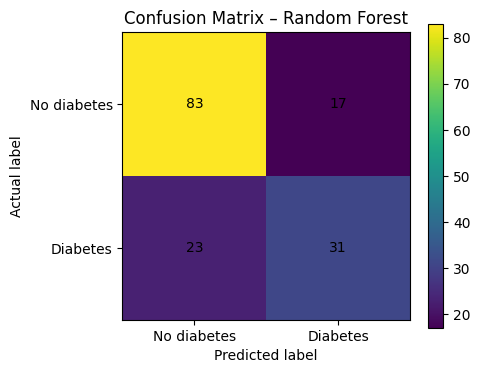

In [29]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Confusion Matrix – Random Forest")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1], ["No diabetes", "Diabetes"])
ax.set_yticks([0, 1], ["No diabetes", "Diabetes"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 10. Select an individual patient

LIME is a local explanation method. We select one record from the test set. Change `patient_position` to investigate another patient.

In [30]:
patient_position = 0

patient = X_test_imputed.iloc[patient_position]
actual_outcome = int(y_test.iloc[patient_position])
patient_array = patient.to_numpy().reshape(1, -1)

class_names = ["No diabetes", "Diabetes"]
predicted_class = int(model.predict(patient_array)[0])
predicted_probabilities = model.predict_proba(patient_array)[0]

display(patient.to_frame(name="Value"))
print("Actual outcome:", class_names[actual_outcome])
print("Predicted outcome:", class_names[predicted_class])
for class_id, probability in enumerate(predicted_probabilities):
    print(f"{class_names[class_id]} probability: {probability:.3f}")

,Value
Pregnancies,7.000
Glucose,159.000
BloodPressure,64.000
SkinThickness,29.000
Insulin,125.000
BMI,27.400
DiabetesPedigreeFunction,0.294
Age,40.000


Actual outcome: No diabetes
Predicted outcome: Diabetes
No diabetes probability: 0.255
Diabetes probability: 0.745


The predicted probability is the model's estimate, not a clinical diagnosis or a guarantee of the patient's actual condition. We will now explain this model prediction using LIME.

## 11. Create a LIME tabular explainer

LIME uses the training data to understand feature distributions. Its prediction function must return class probabilities from the original trained model.

In [31]:
explainer = LimeTabularExplainer(
    training_data=X_train_imputed.to_numpy(),
    feature_names=X_train_imputed.columns.tolist(),
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE
)

def predict_proba_for_lime(samples):
    samples_df = pd.DataFrame(samples, columns=X_train_imputed.columns)
    return model.predict_proba(samples_df)

print("LIME explainer created.")

LIME explainer created.


## 12. Generate the LIME explanation

`explain_instance()` generates modified samples, obtains predictions from the original model, weights samples by proximity and fits a local interpretable model. `num_features` controls how many feature contributions are displayed.

In [32]:
explanation = explainer.explain_instance(
    data_row=patient.to_numpy(),
    predict_fn=predict_proba_for_lime,
    labels=(predicted_class,),
    num_features=8,
    num_samples=5000
)
print("LIME explanation generated.")

LIME explanation generated.


## 13. Visualise and interpret the explanation

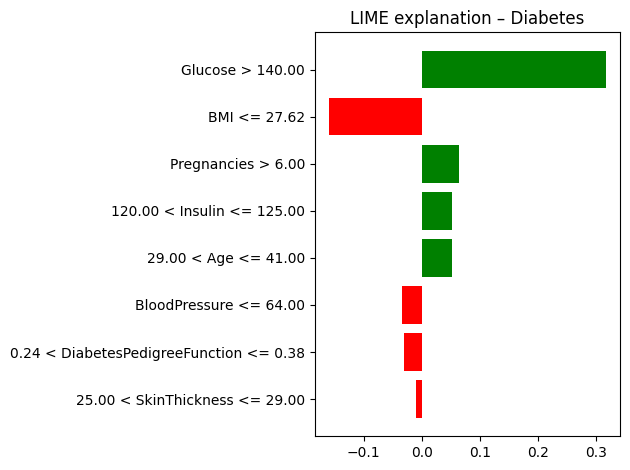

In [33]:
fig = explanation.as_pyplot_figure(label=predicted_class)
plt.title(f"LIME explanation – {class_names[predicted_class]}")
plt.tight_layout()
plt.show()

### 13.1 Read the feature contributions

- A positive contribution for the selected class supports that class in the local explanation.
- A negative contribution opposes the selected class and supports the alternative.
- The feature conditions are part of the local explanation generated by LIME.
- The magnitude indicates the strength of the contribution in this local surrogate explanation.

These are local surrogate-model weights. They are not causal effects and do not prove that changing a feature will change a person's real-world diabetes status.

In [34]:
print("Feature contributions for the predicted class:")
for feature_description, contribution in explanation.as_list(label=predicted_class):
    direction = "supports selected class" if contribution > 0 else "opposes selected class"
    print(f"{feature_description:45s} {contribution: .4f} ({direction})")

Feature contributions for the predicted class:
Glucose > 140.00                               0.3173 (supports selected class)
BMI <= 27.62                                  -0.1606 (opposes selected class)
Pregnancies > 6.00                             0.0647 (supports selected class)
120.00 < Insulin <= 125.00                     0.0514 (supports selected class)
29.00 < Age <= 41.00                           0.0514 (supports selected class)
BloodPressure <= 64.00                        -0.0334 (opposes selected class)
0.24 < DiabetesPedigreeFunction <= 0.38       -0.0308 (opposes selected class)
25.00 < SkinThickness <= 29.00                -0.0103 (opposes selected class)


## 14. Explore another patient

Generate a second explanation. Different patients may have different local explanations, even when they receive the same predicted class.

In [35]:
second_patient_position = min(1, len(X_test_imputed) - 1)
second_patient = X_test_imputed.iloc[second_patient_position]
second_prediction = int(
    model.predict(second_patient.to_numpy().reshape(1, -1))[0]
)

second_explanation = explainer.explain_instance(
    data_row=second_patient.to_numpy(),
    predict_fn=predict_proba_for_lime,
    labels=(second_prediction,),
    num_features=8,
    num_samples=5000
)

print("Second patient prediction:", class_names[second_prediction])
display(second_patient.to_frame(name="Value"))
second_explanation.show_in_notebook(show_table=True, show_all=False)

Second patient prediction: No diabetes


,Value
Pregnancies,10.000
Glucose,68.000
BloodPressure,106.000
SkinThickness,23.000
Insulin,49.000
BMI,35.500
DiabetesPedigreeFunction,0.285
Age,47.000


ImportError: cannot import name 'display' from 'IPython.core.display' (/Users/sachindev/Library/Python/3.13/lib/python/site-packages/IPython/core/display.py)

### 14.1 Compare the explanations

1. Did both patients receive the same predicted class?
2. Are the most influential features the same?
3. Do the directions of feature contributions differ?
4. What does this tell you about local explanations?

**Expected observation:** Explanations can differ because LIME approximates model behaviour around each selected patient. The explanation is specific to that instance's local neighbourhood.

## 15. Limitations of LIME

1. **Local approximation:** It explains behaviour near one instance, not the entire model.
2. **Sampling sensitivity:** Different generated samples or settings can lead to different explanations.
3. **Feature dependence:** Modifying features independently can create unusual or unrealistic combinations, especially when features are correlated.
4. **Model fidelity:** The local surrogate may not perfectly reproduce the original model.
5. **Not causal:** A feature contribution does not establish cause and effect.
6. **Choice of settings:** Number of samples, kernel width, discretisation and number of displayed features can affect the explanation.

**Key takeaway:** LIME provides a local, interpretable approximation of a complex model's behaviour around an individual prediction. It does not guarantee that the original model is accurate, fair or causally correct.

## 16. Hands-on exercises

### Exercise 1 – Select a different patient
Change `patient_position` in Section 10 and regenerate the explanation. Record the predicted class and the three strongest contributions.

### Exercise 2 – Change the number of samples
Generate explanations using `num_samples=1000`, `5000` and `10000`. Compare the feature contributions. Why might the sample count affect the explanation?

### Exercise 3 – Change the number of displayed features
Try `num_features=3` and `num_features=8`. What information is easier to see, and what might be omitted?

### Exercise 4 – Critical thinking
A LIME explanation shows that a feature contributes strongly to a high-risk prediction. Can we conclude that changing this feature will reduce the patient's actual diabetes risk? Justify your answer.

## 18. Practical submission

Submit:
1. Screenshot of Random Forest evaluation results.
2. Screenshot of the LIME explanation for the selected patient.
3. Interpretation of the three strongest feature contributions.
4. Comparison of explanations for two patients.
5. Answers to the hands-on exercises and review questions.

### Expected learning outcome
You should be able to train a classifier, select an individual prediction, generate a LIME explanation and interpret how the model behaves around that particular instance.

